# matplotlib 的绘图函数

这一章介绍常用图形的画法，每个函数都有很多决定属性的关键字参数，这里不全部介绍，需要细调时请看函数的说明或官方的示例。

## 本章要学的内容

- 对数坐标与极坐标
- 柱状图与散点图
- 图像与等高线
- 网格(`pcolormesh`、三角网格)
- 向量场(`quiver`)
- 三维曲面

In [1]:
import numpy as np
import helper.matplotlib
from matplotlib import pyplot as plt
from matplotlib import cm

## 对数坐标的图

`plot()` 的 x 轴与 y 轴都是普通的数轴，而对数坐标用的函数有 3 个。

* `semilogx()`：x 轴取对数
* `semilogy()`：y 轴取对数
* `loglog()`：两个轴都取对数

下面的程序用 4 种坐标画低通滤波器的频率响应，左上角是 `plot()`、右上角是 `semilogx()`、左下角是 `semilogy()`、右下角是 `loglog()`；两个轴都取对数的图叫伯德图。

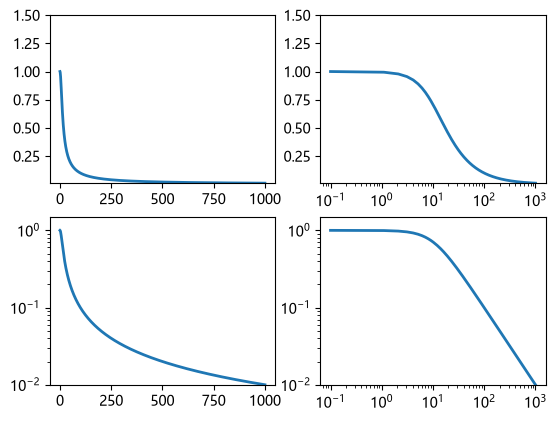

In [2]:
w = np.linspace(0.1, 1000, 1000)
p = np.abs(1 / (1 + 0.1j * w))  # 计算低通滤波器的频率响应

fig, axes = plt.subplots(2, 2)

functions = ("plot", "semilogx", "semilogy", "loglog")

for ax, fname in zip(axes.ravel(), functions):
    func = getattr(ax, fname)
    func(w, p, linewidth=2)
    ax.set_ylim(0.01, 1.5)

## 极坐标的图

极坐标用离中心的角度与距离来表示点，下面的程序画极坐标的图。

(<a list of 4 Line2D ticklines objects>,
 [Text(0.0, 0, '0°'), Text(0.7853981633974483, 0, '45°')])

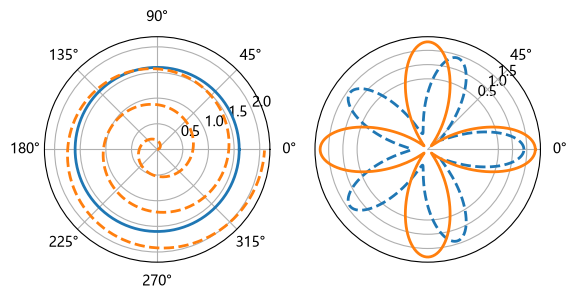

In [3]:
theta = np.arange(0, 2 * np.pi, 0.02)

plt.subplot(121, polar=True)  #❶
plt.plot(theta, 1.6 * np.ones_like(theta), linewidth=2)  #❷
plt.plot(3 * theta, theta / 3, "--", linewidth=2)

plt.subplot(122, polar=True)
plt.plot(theta, 1.4 * np.cos(5 * theta), "--", linewidth=2)
plt.plot(theta, 1.8 * np.cos(4 * theta), linewidth=2)
plt.rgrids(np.arange(0.5, 2, 0.5), angle=45)  #❸
plt.thetagrids([0, 45])  #❹;

❶ 给 `subplot()` 传 `polar=True`，就得到极坐标的子图。❷ 之后用 `plot()` 画曲线，也可以直接用 `polar()` 来做。

❸ `rgrids()` 决定同心圆的半径，以及把文字放在哪个角度上：右图里半径 0.5、1.0、1.5 有 3 个圆，文字沿着 45 度的线排。❹ `thetagrids()` 决定放射状线的角度，右图里是 0 度与 45 度两条。

## 柱状图

柱状图用柱子的长度表示值，适合比较几组数据。下面的程序读入中国按年龄的人口(Wikipedia 的数据，不保证准确)，把男女并排比较。

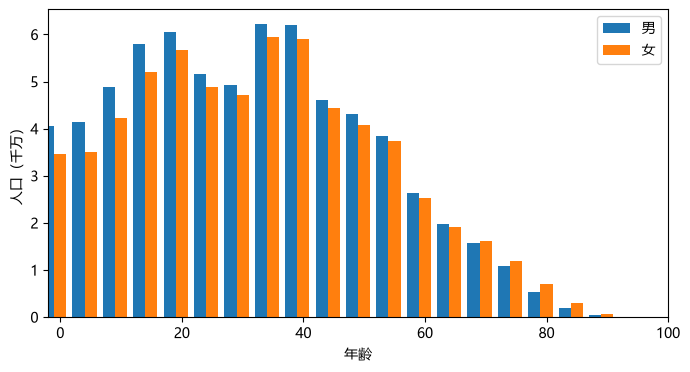

In [4]:
data = np.loadtxt("data/china_population.txt")
width = (data[1, 0] - data[0, 0]) * 0.4  #❶
plt.figure(figsize=(8, 4))
plt.bar(data[:, 0] - width, data[:, 1] / 1e7, width, label="男")  #❷
plt.bar(data[:, 0], data[:, 2] / 1e7, width, label="女")  #❸
plt.xlim(-width, 100)
plt.xlabel("年齢")
plt.ylabel("人口（千万）")
plt.legend();

读进来的数据第 1 列是年龄，也就是横轴。❶ 先决定柱子的宽度：一个年龄要并排两根柱子，所以宽度要比年龄的间隔小，这里取间隔的 0.4 倍。

❷ 用 `bar()` 画男性的柱子，第 1 个参数是柱子左端的 x 坐标：为了让男女的柱子夹住年龄的刻度，把左端取成「年龄 - 宽度」。第 2 个参数是高度、第 3 个参数是宽度，宽度给一个序列就能逐根改变。

❸ 女性的柱子则把左端取成年龄来画。

## 散点图

`plot()` 的格式里只写点，就画成散点图。

```python
plt.plot(np.random.random(100), np.random.random(100), "o")
```

不过这种办法没法逐点改颜色与大小，用 `scatter()` 就能改。

下面的程序是 `scatter()` 的用法。

C:\Users\ruoyu\AppData\Local\Temp\ipykernel_38420\331269464.py:4: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(x, y, s=x * 1000, c=y, marker=(5, 1), alpha=0.8, lw=2, facecolors="none")


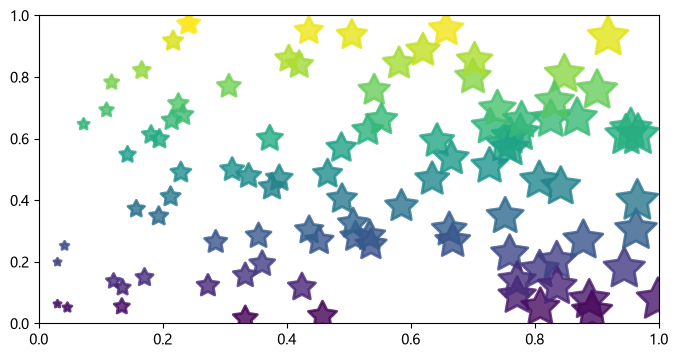

In [5]:
plt.figure(figsize=(8, 4))
x = np.random.random(100)
y = np.random.random(100)
plt.scatter(x, y, s=x * 1000, c=y, marker=(5, 1), alpha=0.8, lw=2, facecolors="none")
plt.xlim(0, 1)
plt.ylim(0, 1);

`scatter()` 的前两个参数是各点的 x 与 y，`s` 是点的面积、`c` 是颜色，两个都可以给单个值或数组；给 `c` 传序列时，颜色由色图决定，默认小值偏蓝、大值偏红。`c` 是形状 `(N, 3)` 或 `(N, 4)` 的二维数组时，可以直接指定 RGB 的颜色。

`marker` 是点的形状，用字符串或两个数的元组来决定：第 1 个是多边形的边数、第 2 个是 0〜3 的种类，0 为多边形、1 为星形、2 为放射状、3 为圆。`alpha` 是透明度、`lw` 是线的粗细，`facecolors="none"` 则不填充。

## 图像

用 `imread()` 与 `imshow()` 能读入并显示图像：`imread()` 把图像变成 NumPy 数组，第 1 个参数是文件名或文件对象，省掉 `format` 时按扩展名决定格式；黑白图是 `(M, N)`、彩色图是 `(M, N, C)` 的数组，其中 `C` 是 3 或 4。

下面的程序读 `vinci_target.png`：读 PNG 会得到归一化到 0.0〜1.0 的 `float32` 数组，所以要用 `(img * 255).astype(np.uint8)` 变回 1 字节。

:::{note}
`imread()` 返回的类型随格式而变：PNG 是 0.0〜1.0 的 `float32`，而 JPEG 保持 8 位的 `uint8`，因为 JPEG 不做归一化。
:::

In [6]:
img = plt.imread("data/vinci_target.png")
img = (img * 255).astype(np.uint8)
print(img.shape, img.dtype)

(505, 375, 3) uint8


用 `imshow()` 显示图像。

❶ 传三维数组时，各通道的值决定颜色。❷ `imshow()` 默认把 y 轴从上往下取，设成 `origin="lower"` 后原点在左下角，但图像会上下颠倒。❸ 三维数组是浮点数时，值的范围要在 0.0〜1.0 内，超出之后颜色就不对了。❹ 把值收在 0〜1 的数组，画出来与原图相同，❺ 用 `clip()` 把范围外的值压住，整体就变亮。

❻ 传二维数组时，颜色由色图决定，这里画的是红色通道：默认小值偏蓝、大值偏红，看上去不自然，用 `colorbar()` 能把对应关系显示出来。❼ 用 `cmap` 可以换色图。

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..242.0].


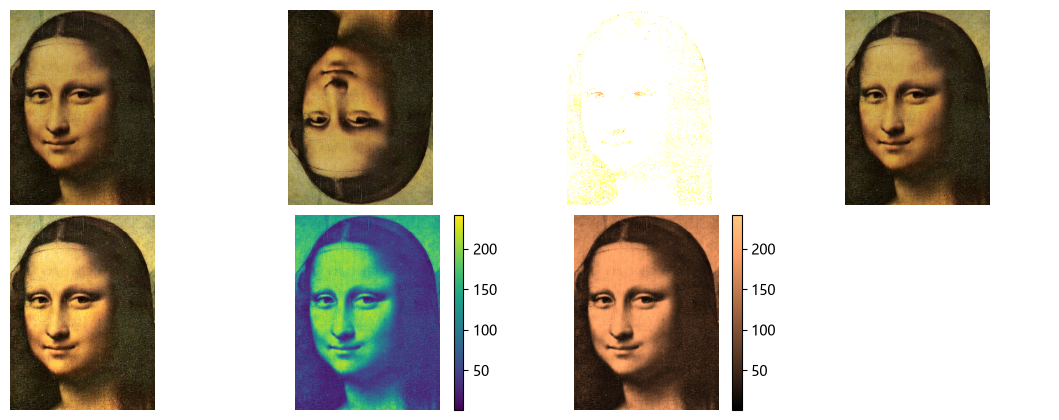

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(11, 4))
fig.subplots_adjust(0, 0, 1, 1, 0.05, 0.05)

axes = axes.ravel()

axes[0].imshow(img)  #❶
axes[1].imshow(img, origin="lower")  #❷
axes[2].imshow(img * 1.0)  #❸
axes[3].imshow(img / 255.0)  #❹
axes[4].imshow(np.clip(img / 200.0, 0, 1))  #❺

axe_img = axes[5].imshow(img[:, :, 0])  #❻
plt.colorbar(axe_img, ax=axes[5])

axe_img = axes[6].imshow(img[:, :, 0], cmap="copper")  #❼
plt.colorbar(axe_img, ax=axes[6])

for ax in axes:
    ax.set_axis_off()

色图是 `ColorMap` 对象，matplotlib 里准备了很多，名字可以用下面的代码查到。

In [8]:
plt.colormaps()[:5]

['magma', 'inferno', 'plasma', 'viridis', 'cividis']

`imshow()` 任何二维数据都能显示，下面的程序把双变量函数 $f(x,y) = x e^{-x^2-y^2}$ 画成图像。

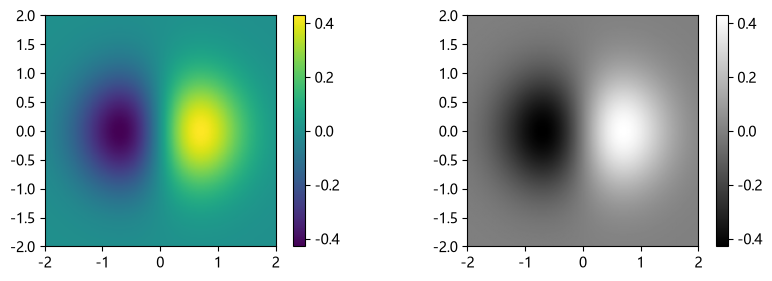

In [9]:
y, x = np.ogrid[-2:2:200j, -2:2:200j]
z = x * np.exp(-(x**2) - y**2)  #❶

extent = [np.min(x), np.max(x), np.min(y), np.max(y)]  #❷

plt.figure(figsize=(10, 3))
plt.subplot(121)
plt.imshow(z, extent=extent, origin="lower")  #❷
plt.colorbar()
plt.subplot(122)
plt.imshow(z, extent=extent, cmap=cm.gray, origin="lower")
plt.colorbar();

❶ 用广播把函数的值算成二维数组 `z`，第 0 轴是 y、第 1 轴是 x。❷ 把 x 与 y 的范围放进 `extent`，❸ 给了 `extent`，轴的刻度就用那个范围。

## 等高线图

双变量的函数也能用等高线表示：等高线是把值相同的点连起来的线，线密的地方值变化快。matplotlib 里用 `contour()` 与 `contourf()`，后者会填上颜色。

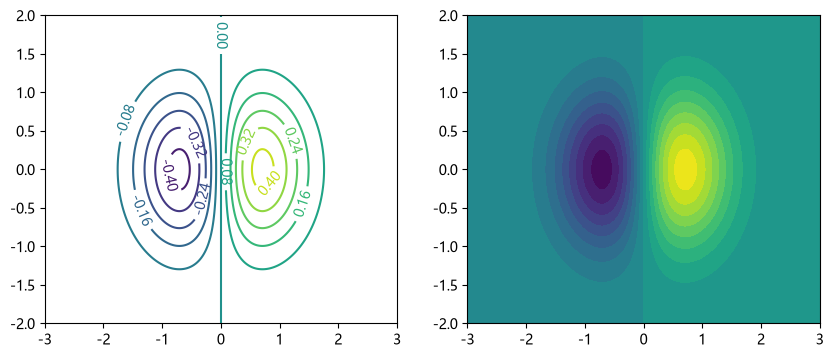

In [10]:
y, x = np.ogrid[-2:2:200j, -3:3:300j]  #❶
z = x * np.exp(-(x**2) - y**2)

extent = [np.min(x), np.max(x), np.min(y), np.max(y)]

plt.figure(figsize=(10, 4))
plt.subplot(121)
cs = plt.contour(z, 10, extent=extent)  #❷
plt.clabel(cs)  #❸
plt.subplot(122)
plt.contourf(x.reshape(-1), y.reshape(-1), z, 20)  #❹;

❶ x 与 y 用不同的范围与分割数，好区分一些；`z` 的形状是 `(200, 300)`，第 0 轴是 y、第 1 轴是 x。

❷ 用 `contour()` 画等高线，第 2 个参数 10 是区间的个数，所以线有 9 条；用 `extent` 可以指定轴的范围。❸ 把 `contour()` 返回的 `QuadContourSet` 传给 `clabel()`，线上就会标出数值。

❹ `contourf()` 会填上颜色，这里换成传 x 与 y 的写法：第 1、第 2 个参数是算 `z` 时用的 x 与 y 的点，可以是 1 维数组，也可以是与 `z` 同形的数组。

:::{tip}
想用散乱的点画等高线时，先用 `scipy.interpolate` 的插值做成网格数据再画。
:::

等高线还能画隐函数的曲线。隐函数是指 $f(x,y)=0$ 决定 x 与 y 的关系，例如 $x^2+y^2-1=0$ 就是单位圆。

这种关系没法像普通函数那样做一串 x 再算 y，所以用等高线：隐函数的曲线就是值为 0 的那条等高线。下面的程序把下面的函数按 $f(x,y)=0$ 与 $f(x,y)-0.1=0$ 画出来。

$$f(x,y)=(x^2+y^2)^4 - (x^2-y^2)^2$$

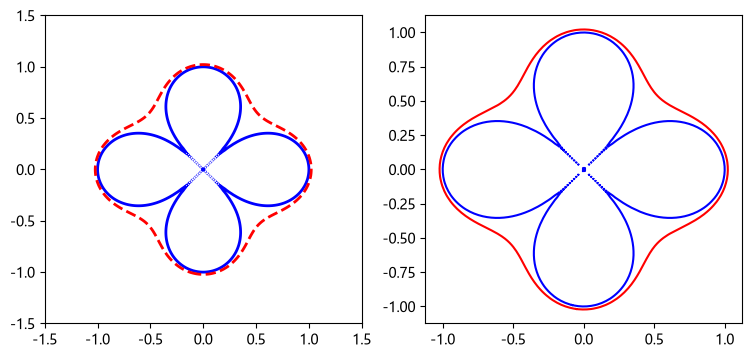

In [11]:
y, x = np.ogrid[-1.5:1.5:200j, -1.5:1.5:200j]
f = (x**2 + y**2) ** 4 - (x**2 - y**2) ** 2

plt.figure(figsize=(9, 4))
plt.subplot(121)
extent = [np.min(x), np.max(x), np.min(y), np.max(y)]
cs = plt.contour(
    f,
    extent=extent,
    levels=[0.0, 0.1],  #❶
    colors=["b", "r"],
    linestyles=["solid", "dashed"],
    linewidths=[2, 2],
)

plt.subplot(122)
for i, p in enumerate(cs.get_paths()):  #❷
    color = cs.get_edgecolors()[i]
    for poly in p.to_polygons():
        plt.plot(poly[:, 0], poly[:, 1], color=color)

❶ 用 `contour()` 的 `levels` 指定等高线的值，这里是 `[0, 0.1]` 所以有 2 条；`colors`、`linestyles`、`linewidths` 分别决定各条线的颜色、线型与粗细。

左图里 $f(x,y)=0$ 的蓝色实线是断开的，因为在原点附近等高线无限靠近，不管把值刻得多细，总有一块分不开；而 $f(x,y)-0.1=0$ 的红色虚线是闭合的。

❷ 从 `cs` 里取出各条等高线的路径，用 `plot()` 重新画一遍。

从 `contour()` 返回的 `QuadContourSet` 的属性里能取到等高线的信息。

In [12]:
print(cs)

每条等高线都有颜色、线型、粗细这些属性，下面的代码取颜色与粗细。

In [13]:
print(cs.get_edgecolors())
print(cs.get_linewidths())

[[0. 0. 1. 1.]
 [1. 0. 0. 1.]]
[2 2]


`get_paths()` 返回做出等高线的所有路径，一条路径也可能分成好几段；用 `to_polygons()` 能把路径变成多边形的列表。这个例子里蓝色的实线由 42 条路径组成。

In [14]:
print(len(cs.get_paths()))
path0 = cs.get_paths()[0]
len(path0.to_polygons())

2


42

路径是 `Path` 对象，所有点的坐标都放在 `vertices` 里。

In [15]:
path1 = cs.get_paths()[1]
path1.vertices

array([[-0.05276382, -1.01841473],
       [-0.05830807, -1.01758794],
       [-0.0678392 , -1.01594938],
       ...,
       [-0.02261307, -1.02126475],
       [-0.03768844, -1.02011677],
       [-0.05276382, -1.01841473]], shape=(545, 2))

## 四边形网格

`pcolormesh(X, Y, C)` 用 `X`、`Y`、`C` 三个数组决定的四边形网格来画图：`X` 与 `Y` 是同形的二维数组，`C` 与它们同形，或者少 1 行 1 列。

四边形的 4 个顶点的 x 坐标由 `X` 相邻的 4 个元素决定，y 坐标由 `Y` 同样的 4 个元素决定，颜色则由 `C` 的值与色图决定。

`shading` 有 3 种写法。

* `'flat'`：`C` 比 `X` 少 1 行 1 列时自动选中。
* `'nearest'`：把 `X` 与 `Y` 各扩大 1 行 1 列，再按 `flat` 画。
* `'gouraud'`：三者同样大小，四边形内部的颜色由 4 个顶点的颜色混合决定。

下面的例子里 `X` 与 `Y` 的形状是 `(2, 3)`，相邻的 4 个元素有两种组合，也就是两个四边形的顶点。

```
 第 1 个四边形的顶点      第 2 个四边形的顶点
=================      ================
(0, 0), (1, 0.2)       (1, 0.2), (2, 0)
(0, 1), (1, 0.8)       (1, 0.8), (2, 1)
```

`C` 的形状是 `(1, 2)`，决定每个四边形的颜色，这时就是 `flat`。把 `X` 与 `Y` 摊平后用 `plot()` 画出顶点，再用 `pcolormesh()` 画出四边形：左边四边形的值是 0.5、右边是 0.8，所以一个偏紫、一个偏黄。

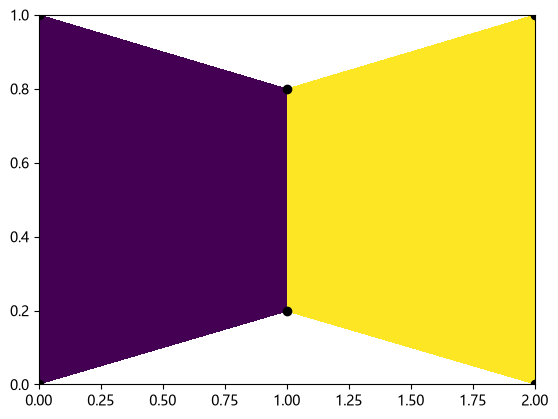

In [16]:
X = np.array([[0, 1, 2], [0, 1, 2]])
Y = np.array([[0, 0.2, 0], [1, 0.8, 1]])
C = np.array([[0.5, 0.8]])

plt.plot(X.ravel(), Y.ravel(), "ko")
plt.pcolormesh(X, Y, C)
plt.margins(0.1);

下面的例子用 `pcolormesh()` 画复平面上的坐标变换，`test_pcolormesh_shading()` 把 3 种写法并排放在一起。

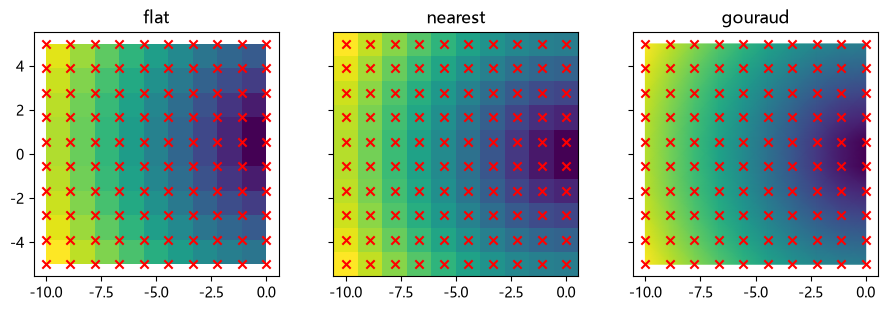

In [17]:
def test_pcolormesh_shading(X, Y, C):
    fig, axes = plt.subplots(
        1, 3, figsize=(9, 3), sharex=True, sharey=True, layout="constrained"
    )
    for ax in axes:
        ax.set_aspect("equal")
    axes[0].set_title("flat")
    axes[0].pcolormesh(X, Y, C[:-1, :-1], shading="flat")
    axes[0].scatter(X, Y, marker="x", color="red")

    axes[1].set_title("nearest")
    axes[1].pcolormesh(X, Y, C, shading="nearest")
    axes[1].scatter(X, Y, marker="x", color="red")

    axes[2].set_title("gouraud")
    axes[2].pcolormesh(X, Y, C, shading="gouraud")
    axes[2].scatter(X, Y, marker="x", color="red")
    return fig


n = 10
x, y = np.mgrid[-10 : 0 : n * 1j, -5 : 5 : n * 1j]
s = x + 1j * y
test_pcolormesh_shading(s.real, s.imag, np.abs(s));

`flat` 里 `X` 与 `Y` 是四边形的顶点、颜色由 `C` 决定；`nearest` 里 `X` 与 `Y` 是四边形的中心；`gouraud` 里 `X` 与 `Y` 是顶点，颜色平滑地变化。

下面的图是用 $z = \frac{2 + s}{2 - s}$ 变换过的网格，这时 `X` 与 `Y` 不是长方形的格子，所以 `nearest` 算不出中心，会出警告。

C:\Users\ruoyu\AppData\Local\Temp\ipykernel_38420\1452107936.py:12: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  axes[1].pcolormesh(X, Y, C, shading="nearest")


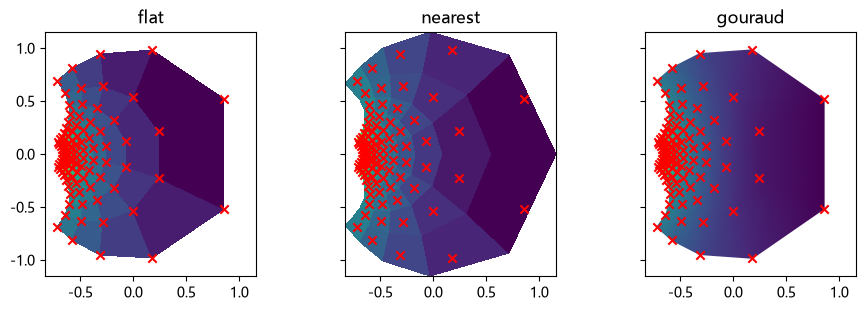

In [18]:
z = (2 + s) / (2 - s)
test_pcolormesh_shading(z.real, z.imag, np.abs(s));

极坐标也能用 `pcolormesh()`：下面的例子用 `mgrid()` 做极坐标的格子，画在 `projection="polar"` 的子图上。

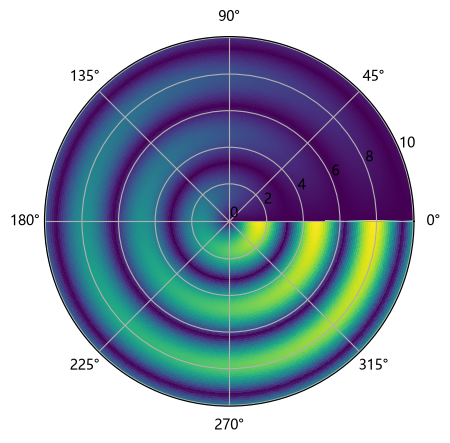

In [19]:
def func(theta, r):
    y = theta * np.sin(r)
    return np.sqrt(y * y)


T, R = np.mgrid[0 : 2 * np.pi : 360j, 0:10:100j]
Z = func(T, R)

ax = plt.subplot(111, projection="polar", aspect=1.0)
ax.pcolormesh(T, R, Z, rasterized=True);

## 三角网格

在制造的解析里，会把对象分成三角形再用有限元法计算，matplotlib 里有显示它用的函数。

* `triplot()`：画出三角形的边
* `tripcolor()`：画出填色的三角形
* `tricontour()`、`tricontourf()`：在三角形上画等高线

`diffusion.txt` 是用 FiPy 把二维定常热传导用有限元法解出来的结果，文件分成 3 个部分。

* `#points`：点的坐标，形状是 `(N_points, 2)`。
* `#triangles`：各三角形 3 个顶点的编号，形状是 `(N_triangles, 3)`。
* `#values`：各三角形的温度，形状是 `(N_triangles, 1)`。

下面的程序把这些数据读进 `data` 字典。

In [20]:
with open("data/diffusion.txt") as f:
    data = {"points": [], "triangles": [], "values": []}
    values = None
    for line in f:
        line = line.strip()
        if not line:
            continue
        if line.startswith("#"):
            values = data[line[1:]]
            continue
        values.append([float(s) for s in line.split()])

data = {key: np.array(data[key]) for key in data}

用 `trip*()` 显示区域里的温度。

❶ `tripcolor()` 的参数是点的 x、点的 y、三角形的顶点编号与值的数组，值既可以对应顶点、也可以对应三角形：这里的 `values` 长度与三角形的个数相同，所以是每个三角形的值；如果长度等于顶点的个数，三角形的值就是 3 个顶点的平均。

❷ 用 `triplot()` 画出三角形的边。❸ 用 `tricontour()` 画等高线，它要求值对应顶点，所以先算出各三角形的重心 `Xc`、`Yc`，把值当作重心的值传进去；不传顶点编号时，由 matplotlib 自己做三角分割。

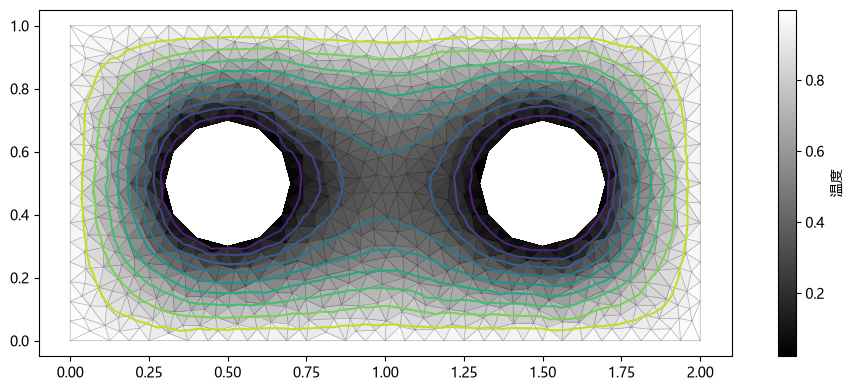

In [21]:
X, Y = data["points"].T
triangles = data["triangles"].astype(int)
values = data["values"].squeeze()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.set_aspect("equal")

mapper = ax.tripcolor(X, Y, triangles, values, cmap="gray")  #❶
plt.colorbar(mapper, label="温度")

plt.triplot(X, Y, triangles, lw=0.5, alpha=0.3, color="k")  #❷

Xc = X[triangles].mean(axis=1)
Yc = Y[triangles].mean(axis=1)
plt.tricontour(Xc, Yc, values, 10)  #❸;

## 箭头图

`quiver()` 用许多箭头表示向量场，下面的程序画 $f(x,y) = x e^{-x^2-y^2}$ 的梯度，其中 `vec_field()` 用数值近似偏微分。

`quiver()` 的前 5 个参数是箭头的起点 `X`、`Y`，方向与大小的 `U`、`V`，以及值的 `C`。

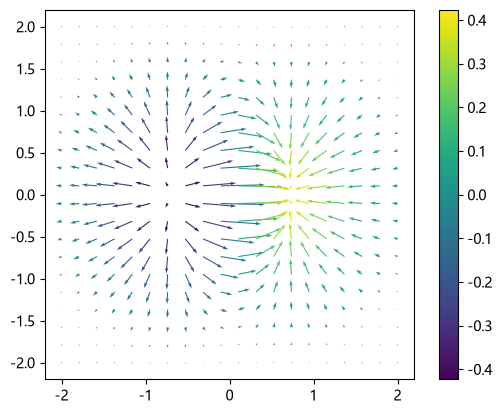

In [22]:
def f(x, y):
    return x * np.exp(-(x**2) - y**2)


def vec_field(f, x, y, dx=1e-6, dy=1e-6):
    x2 = x + dx
    y2 = y + dy
    v = f(x, y)
    vx = (f(x2, y) - v) / dx
    vy = (f(x, y2) - v) / dy
    return vx, vy


X, Y = np.mgrid[-2:2:20j, -2:2:20j]
C = f(X, Y)
U, V = vec_field(f, X, Y)
plt.quiver(X, Y, U, V, C)
plt.colorbar()
plt.gca().set_aspect("equal")

箭头的大小与朝向由很多参数决定。

* 长度由 `scale` 与 `scale_units` 决定，`scale_units` 可以从 `'width'`、`'height'`、`'dots'`、`'inches'`、`'x'`、`'y'`、`'xy'` 里选，长度是「向量的长度 × 单位 ÷ scale」；例如 `scale=2`、`scale_units='x'`、向量长度为 3 时，箭头就是 x 轴的 1.5 个单位。

* `width`、`headwidth`、`headlength`、`headaxislength` 决定轴的粗细与箭头的大小，`units` 是它们的单位。

* `pivot` 是旋转的中心，从 `'tail'`、`'middle'`、`'tip'` 里选。

* `angles` 是决定朝向的方式，有 `'uv'` 与 `'xy'` 两种：`'uv'` 只看 `U` 与 `V`，两者相等时就是 45 度；`'xy'` 还会考虑轴的缩尺。

![quiver 各参数的含义](images/quiver_arrow.png)

用两个例子看它的用法，第一个在参数方程给出的曲线上，等间隔画 40 个箭头，朝向是曲线的切线，颜色是参数的值。

长度的单位由 `scale_units` 与 `units` 决定，这里两个都是 `'dots'`(像素)。把 `dx` 与 `dy` 的长度设成 1、`scale=1.0/arrow_size`，箭头的长度就是 `arrow_size` 个像素；轴的宽度用 `width` 设成 1 像素，`headwidth` 等则是相对于轴宽度的比。这个例子里箭头占满了整个长度，所以看不见轴。

因为 x 轴与 y 轴的缩尺不同，所以把 `angles="xy"`，让箭头贴着切线。

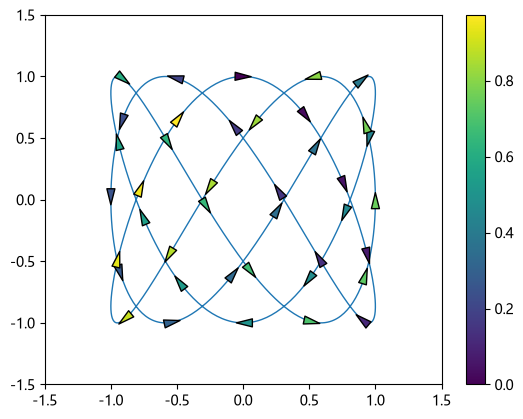

In [23]:
n = 40
arrow_size = 16
t = np.linspace(0, 1, 1000)
x = np.sin(3 * 2 * np.pi * t)
y = np.cos(5 * 2 * np.pi * t)
(line,) = plt.plot(x, y, lw=1)

lengths = np.cumsum(np.hypot(np.diff(x), np.diff(y)))
length = lengths[-1]
arrow_locations = np.linspace(0, length, n, endpoint=False)
index = np.searchsorted(lengths, arrow_locations)
dx = x[index + 1] - x[index]
dy = y[index + 1] - y[index]
ds = np.hypot(dx, dy)
dx /= ds
dy /= ds
plt.quiver(
    x[index],
    y[index],
    dx,
    dy,
    t[index],
    units="dots",
    scale_units="dots",
    angles="xy",
    scale=1.0 / arrow_size,
    pivot="middle",
    edgecolors="black",
    linewidths=1,
    width=1,
    headwidth=arrow_size * 0.5,
    headlength=arrow_size,
    headaxislength=arrow_size,
    zorder=100,
)
plt.colorbar()
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5]);

也可以给起点与终点来画箭头，下面的例子画神经网络的结构：把 `scale_units` 与 `angles` 设成 `"xy"`、`scale` 设成 1，箭头的长度就是数据坐标里的长度。

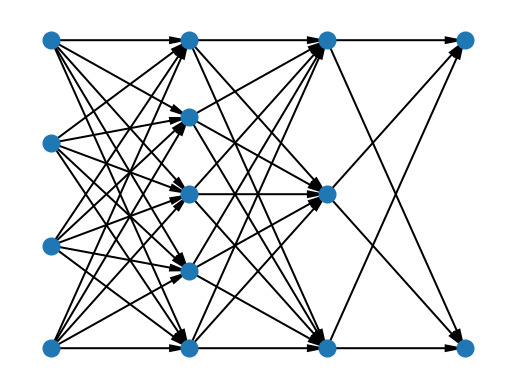

In [24]:
levels = [4, 5, 3, 2]
x = np.linspace(0, 1, len(levels))

for i in range(len(levels) - 1):
    j = i + 1
    n1, n2 = levels[i], levels[j]
    y1, y2 = np.mgrid[0 : 1 : n1 * 1j, 0 : 1 : n2 * 1j]
    x1 = np.full_like(y1, x[i])
    x2 = np.full_like(y2, x[j])
    plt.quiver(
        x1,
        y1,
        x2 - x1,
        y2 - y1,
        angles="xy",
        units="dots",
        scale_units="xy",
        scale=1,
        width=2,
        headlength=10,
        headaxislength=10,
        headwidth=4,
    )

yp = np.concatenate([np.linspace(0, 1, n) for n in levels])
xp = np.repeat(x, levels)
plt.plot(xp, yp, "o", ms=12)
plt.gca().axis("off")
plt.margins(0.1, 0.1);

## 三维的图

用 `mpl_toolkits.mplot3d` 能画三维的图，不过它是用二维的绘制假装成三维，所以不适合大的数据；真正要求的三维可视化请看 PyVista 那一章。

下面是三维曲面。

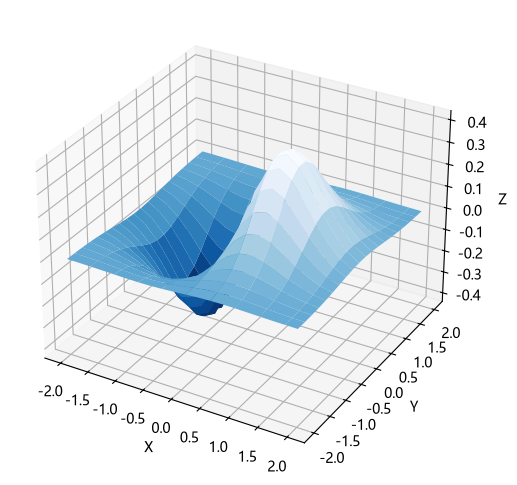

In [25]:
import mpl_toolkits.mplot3d  #❶

x, y = np.mgrid[-2:2:20j, -2:2:20j]  #❷
z = x * np.exp(-(x**2) - y**2)

fig = plt.figure(figsize=(8, 6))
ax = plt.subplot(111, projection="3d")  #❸
ax.plot_surface(x, y, z, rstride=2, cstride=1, cmap=plt.cm.Blues_r)  #❹
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z");

❶ 读入 `mplot3d`，三维的功能都在这个模块里。❷ 用 `mgrid` 做 x-y 平面的格子，再算各点的高度 `z`：三维曲面要求 x、y、z 都是同形的二维数组，所以用 `ogrid` 做不出来；与 `imshow()` 不同的是，第 0 轴是 x 还是 y 都可以，这里第 0 轴是 x、第 1 轴是 y。

❸ 用 `projection="3d"` 做子图，返回的是 `Axes3D`。

:::{admonition} 投影模式
:class: note
投影模式是把数据的坐标变换成屏幕坐标的方式，能用的名字可以用下面的命令查到。

```ipython
>>> from matplotlib import projections
>>> projections.get_projection_names()
['3d', 'aitoff', 'hammer', 'lambert', 'mollweide', 'polar', 'rectilinear']
```

读入 `mplot3d` 之后，这个一览里就多了 `'3d'`；`'aitoff'`、`'hammer'`、`'lambert'`、`'mollweide'` 是地图的投影，`'polar'` 是极坐标，`'rectilinear'` 是默认的直线投影。
:::

❹ 用 `Axes3D` 的 `plot_surface()` 画曲面：`x`、`y`、`z` 都是形状 `(20, 20)` 的二维数组，`cmap` 决定高度与颜色的对应，`rstride` 与 `cstride` 是数组第 0 轴与第 1 轴上每隔几个画一次；数组很大时把间隔调大就快。

`Axes3D` 里还有别的三维绘制方法，请看官方的示例。

## 小结

* 对数坐标用 `semilogx()`、`semilogy()`、`loglog()`，两个轴都取对数的图叫伯德图。
* 极坐标用 `subplot(polar=True)` 或 `polar()` 来做，用 `rgrids()` 与 `thetagrids()` 决定格子。
* 柱状图用 `bar()`；`plot()` 的格式里只写点也能画散点图，但要逐点变化就用 `scatter()`。
* 图像用 `imread()` 与 `imshow()`，PNG 返回 0〜1 的 `float32`、JPEG 返回 `uint8`。
* 等高线用 `contour()` 与 `contourf()`，用 `levels` 选值就能画隐函数的曲线。
* 格子用 `pcolormesh()` 上色，三角形用 `triplot()`、`tripcolor()`、`tricontour()` 画。
* 向量场用 `quiver()`，长度由 `scale` 与 `scale_units` 决定、朝向由 `angles` 决定。
* 三维用 `mplot3d` 的 `Axes3D`，数据重的时候用 PyVista。